### Theory

**Log scale**

log scale: distance between 2 points is proportional to their distance in decades  
so distance from 0 to 1  is equal to distance from 1 to 10  
can't draw 0, bc would be at $- \infty$  

decade:  
$dex(a,b) = \log_{10} (\frac{b}{a})$  
so the number of 0s of difference (the difference in the exponents of the power of 10)    
eg: 10, 1000 distano 2 decadi  

**Bi-logarithmic scale (LogLog)**

for power law $\;y = Ax^b$  

- A: y(1), intercept with axis x=1  

- b: tangent of line, angular coeff  
    - choose 2 points $(x_0, y_0), (x_1, y_1)$ (real values found on axes)
    - tangent in loglog paper is:  $b = \frac{log(y_1)-log(y_0)}{log(x_1)-log(x_0)}$

can extimate b by eye, imagine the line drawn in linear axes, what would be its angular coeff? that is b  
0 don't exist in this scale, origin generally at (1,1)


**Semi-logarithmic scale (Semi-Log)**

for exponential law $\;y = ce^{-\lambda x}$ 

- c = y(0), intercept when x=0  
- $\lambda$ = slope = $\frac{ln(y_1)- ln(y_0)}{x_1 -x_0}  $  

log scale only on y axis  
0 exists only in x axis, not in y axis

**Notes on exponential laws** 

$\lambda$: decay constant  
$\tau = \frac{1}{\lambda}$: average life  
$T_{1/2} = \tau  \: ln(2) $: time of halving

how to extimate $\lambda$ from graph:  
si traccia la retta orizzontale con ordinata pari ad 1/2 del valore iniziale ed il valore delle ascisse
per cui essa intercetta con la retta di best-fit corrisponde al tempo di dimezzamento  
this comes from the last formula    


### Practice

2 methods to make logarithm graph  
when in formula i'm asked a logarithm, like $ln x$, can either:  

1. plug normal points, but with log axes  
2. plug ln(x) points in LINEAR axes  

CANNOT DO BOTH ln(x) points and log axes, don't work  

**Which values have log scale?**

power law: both x and y axis have log scale  
exponential law: only y axis has log scale  

**Power law**

$y=Ax^b$  
$\ln y = \ln A + b \ln x$  
$y' = bx' + \ln A$  

**Exponential law**

$y=ce^{\lambda x}$  
$\ln y = \ln c + \lambda x$  
$y' = \lambda x + \ln c$  


**Example: power law**

i have $y=Ax^n$  
want to plot x and y to get n and A  

### Code power law

In [81]:
import numpy as np
from matplotlib import pyplot as plt
from scipy.optimize import curve_fit

In [82]:
# Get data

x = np.array([4.76, 6.345,  9.125,  9.13,  11.115])
y = np.array([3.352, 8.359, 24.816, 24.82, 44.827])

sigma_x = np.full(len(x), 0.1)
sigma_y = np.full(len(x), 0.5)

#### Real points on log axes

In [83]:
def power_law(x, norm, index):
    """Modello di tipo legge di potenza"""
    return norm * (x**index)

In [84]:
# Fit

popt, pcov = curve_fit(power_law, x,y)
norm_hat, index_hat = popt
sigma_norm, sigma_index = np.sqrt(pcov.diagonal())

print(f'A = {norm_hat:.2f} + {sigma_norm:.2f}\n',
      f'n = {index_hat:.2f} + {sigma_index:.2f}')

A = 0.03 + 0.00
 n = 3.01 + 0.01


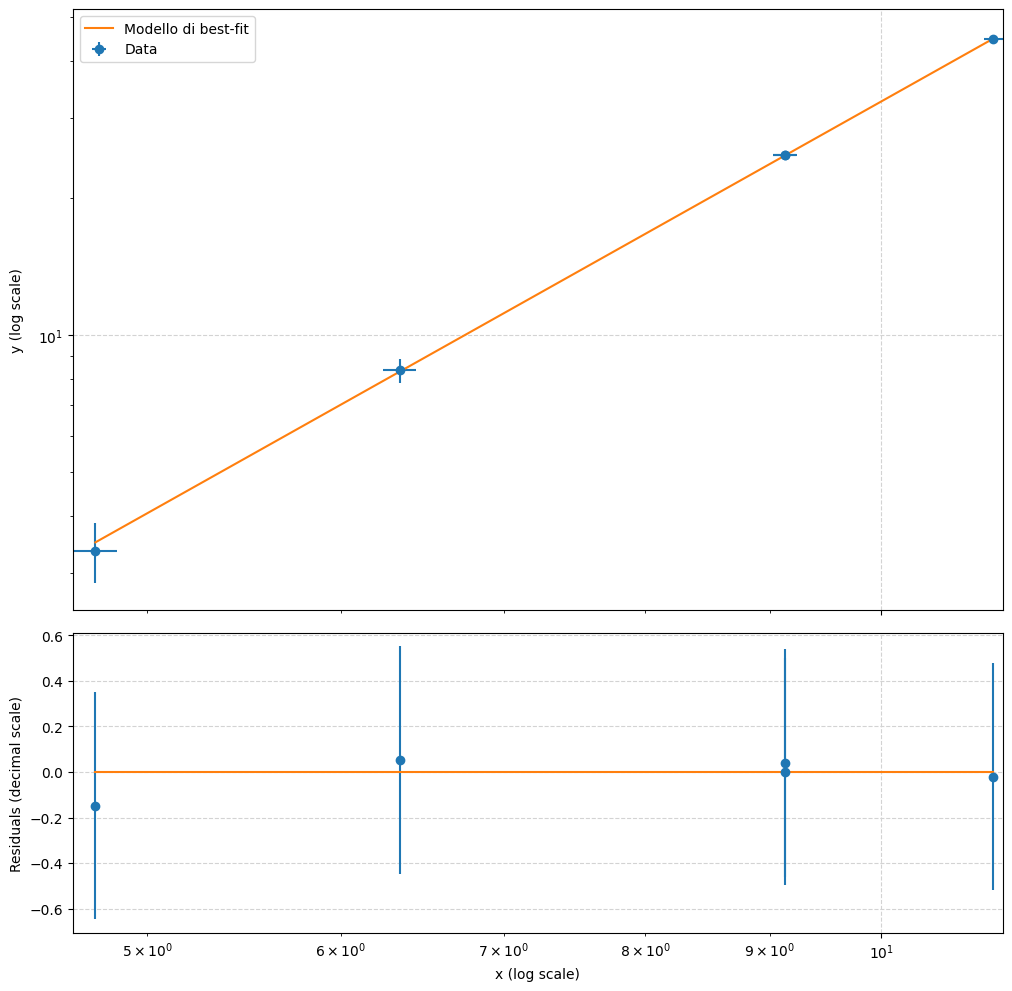

In [85]:
# Fit
model=power_law
res = y - model(x, *popt)

# Create the main figure
fig = plt.figure(figsize=(12, 12))
ax1, ax2 = fig.subplots(2, 1, sharex=True, gridspec_kw=dict(height_ratios=[2, 1], hspace=0.05))
xgrid = np.linspace(x.min(), x.max(), 1000)

# Main plot: the scatter plot of x vs. y, on the top panel.
ax1.errorbar(x, y, xerr=sigma_x, yerr=sigma_y, fmt='o', label='Data')
ax1.plot(xgrid, model(xgrid, *popt), label='Modello di best-fit')
ax1.set_xscale('log')      # scala logaritmica sull’asse x di ax1
ax1.set_yscale('log')      # (se vuoi mettere anche l’asse y in scala log)

# And now the residual plot, on the bottom panel.
ax2.errorbar(x, res, sigma_y, fmt='o')
ax2.plot(xgrid, np.full(xgrid.shape, 0.0)) # horizontal line at y=0

# STYLING  

ax1.set_ylabel('y (log scale)')
ax1.grid(color='lightgray', ls='dashed')
ax1.legend()

ax2.set_xlabel('x (log scale)')
ax2.set_ylabel('Residuals (linear scale)')
ax2.grid(color='lightgray', ls='dashed')

plt.xlim(x.min()-0.1, x.max()+0.1)
fig.align_ylabels((ax1, ax2))

plt.show()

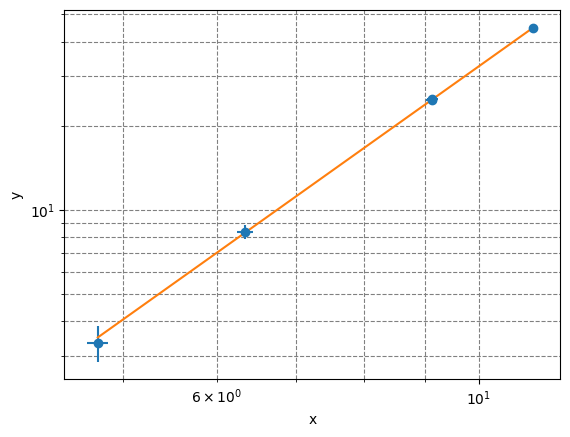

In [86]:
# Plot

t = np.linspace(x.min(), x.max(), 1000)
plt.errorbar(x,y, yerr=sigma_y, xerr=sigma_x, fmt='o')
plt.plot(t, power_law(t, *popt))  # power_law(t, norm_hat, index_hat)

plt.xscale('log')   # if exponential in semi-log, DO NOT PUT THIS LINE
plt.yscale('log')

plt.xlabel('x')
plt.ylabel('y')
plt.grid(which='both', ls='dashed', color='gray')

plt.show()


#### Log points on real axes

In [87]:
def linear(x, m, q):
    return m*x + q

A = 0.029 ± 0.001
n = 3.051 ± 0.049


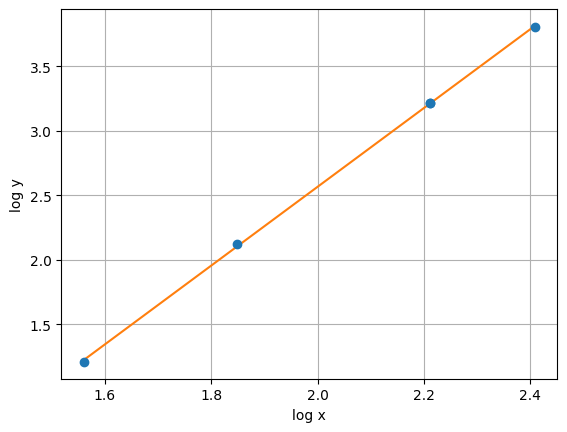

In [88]:
# Get log data

logx = np.log(x)     # if exponential in semi-log, DO NOT PUT THIS LINE, use simply x  
logy = np.log(y)

popt, pcov = curve_fit(linear, logx, logy)
index_hat, log_norm_hat = popt
norm_hat = np.exp(log_norm_hat)

# Get uncertainties (optional)
sigma_log_norm, sigma_index = np.sqrt(np.diag(pcov))
sigma_norm = norm_hat * sigma_log_norm  # error propagation

# Print results
print(f"A = {norm_hat:.3f} ± {sigma_norm:.3f}")
print(f"n = {index_hat:.3f} ± {sigma_index:.3f}")

t = np.linspace(min(logx), max(logx), 100)
plt.errorbar(logx, logy, fmt='o')
plt.plot(t, linear(t, index_hat, log_norm_hat))

plt.xlabel('log x')
plt.ylabel('log y')

plt.grid()
plt.show()

### Code exponental law

In [89]:
import numpy as np
from matplotlib import pyplot as plt
from scipy.optimize import curve_fit

In [90]:
x = np.array([
 0.        , 0.35714286, 0.71428571, 1.07142857, 1.42857143,
 1.78571429, 2.14285714, 2.5       , 2.85714286, 3.21428571,
 3.57142857, 3.92857143, 4.28571429, 4.64285714, 5.0
])

y = np.array([
   3.67384995,  4.59309619,  6.59920559,  9.50357802, 10.71801830,
  14.26262167, 22.50359517, 27.84641274, 32.79880333, 48.28045638,
  58.11686547, 77.31807212,110.52508772,116.12727287,158.13146220
])

sigma_x = np.full(len(x), 0.1)
sigma_y = np.full(len(x), 0.5)


In [91]:
# Get data

np.random.seed(42)
x = np.linspace(0, 5, 15)
c = 3.5
lam = 0.8
y_true = c * np.exp(lam * x)
noise = np.random.normal(scale=0.1 * y_true, size=y_true.shape)
y = y_true + noise

sigma_x = np.full(len(x), 0.1)
sigma_y = np.full(len(x), 0.5)

In [92]:
def exponential(x, A, B):
    """Modello esponenziale: y = A * exp(B * x)"""
    return A * np.exp(x/B)

In [93]:
def exponential_decay(t, theta0, tau):
    return theta0 * np.exp(-t / tau)

# the difference in the functions is if there is the - at the exponent or not 
# check what the experiment says  

In [94]:
# Fit

popt, pcov = curve_fit(exponential, x,y)
norm_hat, index_hat = popt
sigma_norm, sigma_index = np.sqrt(pcov.diagonal())

print(f'theta_0 = {norm_hat:.2f} + {sigma_norm:.2f}\n',
      f'tau = {index_hat:.2f} + {sigma_index:.2f}')

theta_0 = 5.02 + 0.60
 tau = 1.45 + 0.06


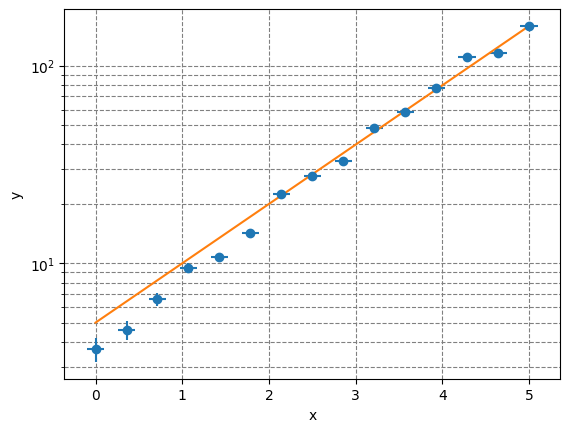

In [95]:
# Plot

t = np.linspace(x.min(), x.max(), 1000)
plt.errorbar(x,y, yerr=sigma_y, xerr=sigma_x, fmt='o')
plt.plot(t, exponential(t, *popt))

# xscale is not log in exponential law
plt.yscale('log')

plt.xlabel('x')
plt.ylabel('y')
plt.grid(which='both', ls='dashed', color='gray')

plt.show()

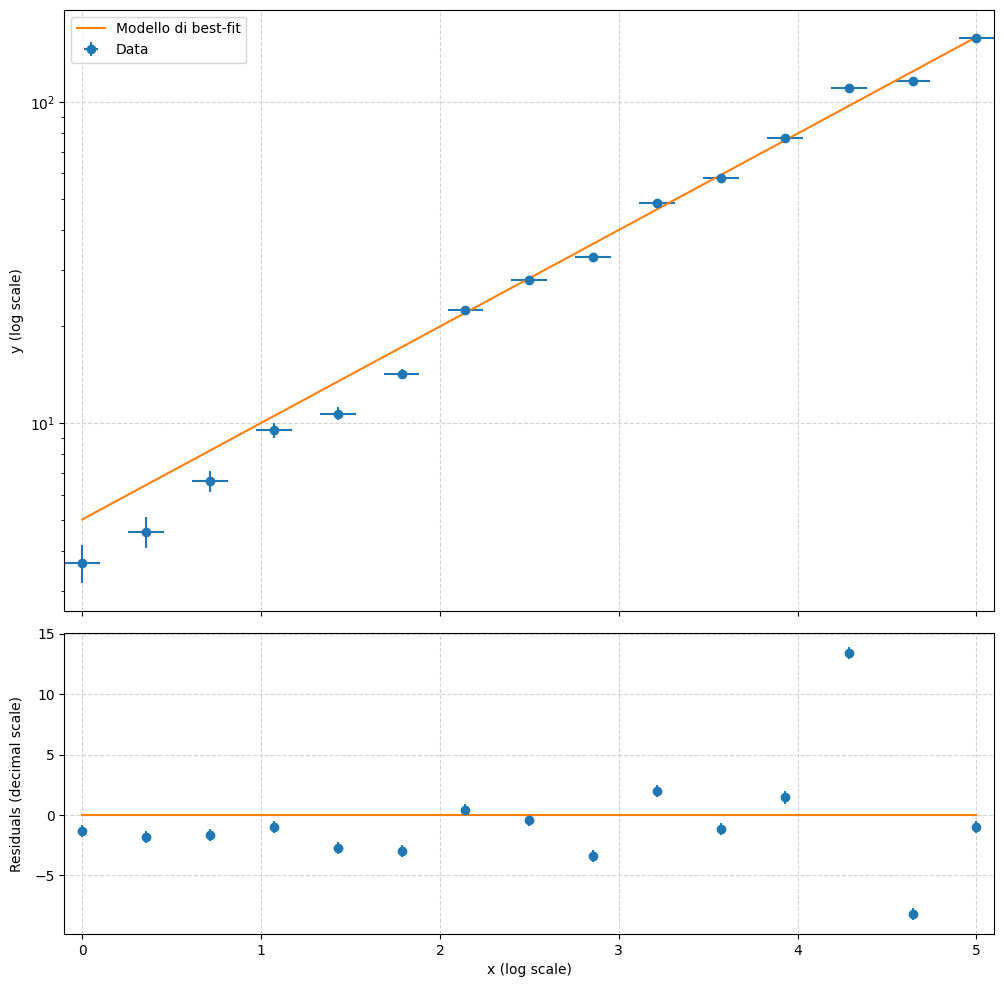

In [96]:
# Fit
model=exponential
res = y - model(x, *popt)

# Create the main figure
fig = plt.figure(figsize=(12, 12))
ax1, ax2 = fig.subplots(2, 1, sharex=True, gridspec_kw=dict(height_ratios=[2, 1], hspace=0.05))
xgrid = np.linspace(x.min(), x.max(), 1000)

# Main plot: the scatter plot of x vs. y, on the top panel.
ax1.errorbar(x, y, xerr=sigma_x, yerr=sigma_y, fmt='o', label='Data')
ax1.plot(xgrid, model(xgrid, *popt), label='Modello di best-fit')
ax1.set_yscale('log')      # (se vuoi mettere anche l’asse y in scala log)

# And now the residual plot, on the bottom panel.
ax2.errorbar(x, res, sigma_y, fmt='o')
ax2.plot(xgrid, np.full(xgrid.shape, 0.0)) # horizontal line at y=0

# STYLING  

ax1.set_ylabel('y (log scale)')
ax1.grid(color='lightgray', ls='dashed')
ax1.legend()

ax2.set_xlabel('x (log scale)')
ax2.set_ylabel('Residuals (linear scale)')
ax2.grid(color='lightgray', ls='dashed')

plt.xlim(x.min()-0.1, x.max()+0.1)
fig.align_ylabels((ax1, ax2))

plt.show()